# unimatrix-zero 01 · Backtests with costs

`unimatrix-zero` simulates portfolios built from `neural-processor` signals on vinculum's
point-in-time universes:

- **returns**: daily total returns by security, linked across holding-company reorganizations,
  with a delisting return when a stock stops trading (its last close, or -30% after a collapse);
- **execution**: weights formed at a month-end close trade at the next day's close (`lag=1`),
  then drift with prices until the next rebalance;
- **costs**: half-spread fitted on measured trades and quotes (from dollar volume, volatility
  and the year; decision 0017), 1 bp commission, 25 bp a year to borrow
  (300 bp for hard-to-borrow names) and, given an AUM, square-root market impact.

1. signals and a first backtest
2. what each assumption changes
3. value, quality, momentum and the combination
4. long and short legs, exposures
5. capacity
6. long-only
7. caveats

In [1]:
import matplotlib.pyplot as plt
import polars as pl
from massive_subspace_stream import Store
from neural_processor import Processor, composite
from subspace_probe import style, timed
from unimatrix_zero import NO_COSTS, CostModel, Engine, quantile_weights, top_n_weights
from vinculum import Vinculum

style()
pl.Config.set_tbl_rows(30)
pl.Config.set_tbl_width_chars(200)
pl.Config.set_tbl_cols(16)
v, massive = Vinculum(), Store()
p, eng = Processor(vinculum=v, store=massive), Engine(vinculum=v, store=massive)
START, TOP = "2012-01-01", 1000
VALUE = ["earnings_yield", "book_to_market", "fcf_yield", "ebitda_to_ev"]
QUALITY = ["roe", "gross_profitability", "cash_roa", "accruals"]
with timed("signal panel"):
    sig = p.panel([*VALUE, *QUALITY, "momentum_12_1"], start=START, top=TOP)
sig = composite(sig, VALUE, name="value", min_signals=2)
sig = composite(sig, QUALITY, name="quality", min_signals=2)
sig = composite(sig, ["momentum_12_1"], name="momentum")
sig = composite(sig, {"value": 1, "quality": 1, "momentum": 1}, name="combined", min_signals=2)
print(f"{sig.height:,} rows, {sig['date'].n_unique()} month ends")


def show(bt, label):
    s = bt.summary().filter(pl.col("series") == "net").row(0, named=True)
    g = bt.summary().filter(pl.col("series") == "gross").row(0, named=True)
    return {"portfolio": label, "gross_return": g["ann_return"], "net_return": s["ann_return"],
            "net_vol": s["ann_vol"], "gross_sharpe": g["sharpe"], "net_sharpe": s["sharpe"], "t_stat": s["t_stat"],
            "max_drawdown": s["max_drawdown"], "turnover_per_year": s["turnover_per_year"], "cost_drag": s["cost_drag"],
            "beta": s.get("beta")}


def table(rows):
    return pl.DataFrame(rows).with_columns(pl.col(pl.Float64).round(3))

signal panel: 3.50 s
179,000 rows, 179 month ends


## 1 · A first backtest

Long the top fifth of the top 1,000 on the combined score, short the bottom fifth, equal
weights, monthly, default costs, trading the day after the signal.

In [2]:
w = quantile_weights(sig, "combined", q=0.2)
with timed("backtest"):
    bt = eng.run(w)
bt.summary().with_columns(pl.col(pl.Float64).round(3))

backtest: 29.58 s


series,ann_return,ann_vol,sharpe,t_stat,max_drawdown,start,end,years,turnover_per_rebalance,turnover_per_year,cost_drag,avg_gross_exposure,avg_net_exposure,beta,alpha
str,f64,f64,f64,f64,f64,date,date,f64,f64,f64,f64,f64,f64,f64,f64
"""net""",0.055,0.1,0.59,2.266,-0.166,2012-02-01,2026-11-12,14.75,0.933,11.253,0.008,2.005,0.003,-0.021,0.062
"""gross""",0.064,0.1,0.669,2.571,-0.164,null,null,null,null,null,null,null,null,null,null
"""long leg""",0.145,0.182,0.837,3.215,-0.368,null,null,null,null,null,null,null,null,null,null
"""short leg""",-0.099,0.195,-0.44,-1.689,-0.824,null,null,null,null,null,null,null,null,null,null


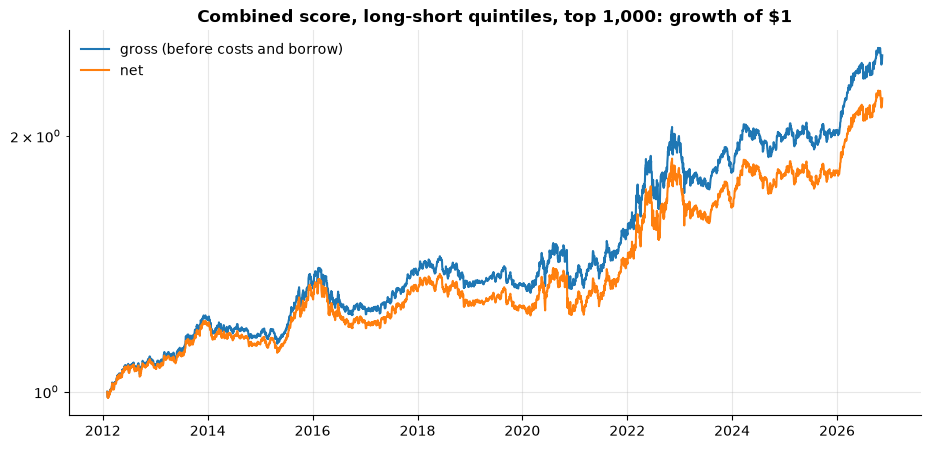

year,gross,net,long,short,turnover,cost,borrow
i32,f64,f64,f64,f64,f64,f64,f64
2012,0.077,0.068,0.1,-0.041,11.886,0.006,0.002
2013,0.129,0.121,0.428,-0.223,10.783,0.005,0.003
2014,-0.043,-0.05,0.064,-0.116,10.087,0.004,0.003
2015,0.145,0.137,-0.011,0.133,10.994,0.005,0.002
2016,-0.058,-0.065,0.092,-0.158,11.728,0.005,0.003
2017,0.095,0.087,0.258,-0.135,10.817,0.005,0.002
2018,-0.021,-0.029,-0.102,0.064,10.225,0.005,0.003
2019,-0.009,-0.017,0.287,-0.244,11.917,0.005,0.003
2020,0.003,-0.007,0.232,-0.271,12.728,0.008,0.003


In [3]:
d = bt.daily.with_columns((1 + pl.col("gross")).cum_prod().alias("nav_gross"))
fig, ax = plt.subplots(figsize=(11, 5))
ax.plot(d["date"], d["nav_gross"], label="gross (before costs and borrow)")
ax.plot(d["date"], d["nav"], label="net")
ax.set_yscale("log")
ax.set_title("Combined score, long-short quintiles, top 1,000: growth of $1")
ax.legend()
plt.show()
bt.by_year().with_columns(pl.col(pl.Float64).round(3))

The long leg earns most of the return; the short leg loses money in most years, as the shorted
stocks rise with the market, but less than the long leg makes. Turnover is about 11 times a
year (two-sided, as a multiple of capital), which costs under one percentage point a year
including borrow: the top 1,000 trade at half-spreads of a few basis points.

No trade here tripped the backtester's cost guard: a trade that costs more than 100 bp per unit
traded is listed in `bt.cost_warnings` and reported in a warning (under the former volume rule,
14 trades in two thin ADRs did). Section 5 looks at what it flags at size; the runs below
silence it.

## 2 · What each assumption changes

The same weights, one assumption at a time:

In [4]:
import warnings

warnings.simplefilter("ignore")   # cost warnings: see section 5
variants = [
    ("no costs, trade at the signal close", dict(costs=NO_COSTS, lag=0)),
    ("no costs, next-day close", dict(costs=NO_COSTS, lag=1)),
    ("default costs, next-day close", dict()),
    ("costs from the noisy spread estimate", dict(costs=CostModel(spread="estimate"))),
    ("delisting at last close only", dict(delisting="last")),
    ("no names under $5", dict(min_price=5.0)),
]
rows = []
with timed(f"{len(variants)} backtests"):
    for label, kw in variants:
        rows.append(show(eng.run(w, **kw), label))
    rows.append(show(eng.run(quantile_weights(sig, "combined", q=0.2, sector_neutral=True)), "sector neutral"))
    rows.append(show(eng.run(quantile_weights(sig, "combined", q=0.2, weighting="cap")), "cap weighted"))
table(rows)

6 backtests: 264.85 s


portfolio,gross_return,net_return,net_vol,gross_sharpe,net_sharpe,t_stat,max_drawdown,turnover_per_year,cost_drag,beta
str,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
"""no costs, trade at the signal …",0.068,0.068,0.1,0.712,0.712,2.733,-0.158,11.266,0.0,-0.021
"""no costs, next-day close""",0.064,0.064,0.1,0.669,0.669,2.571,-0.164,11.252,0.0,-0.021
"""default costs, next-day close""",0.064,0.055,0.1,0.669,0.59,2.266,-0.166,11.253,0.008,-0.021
"""costs from the noisy spread es…",0.064,0.034,0.1,0.669,0.38,1.46,-0.191,11.253,0.03,-0.019
"""delisting at last close only""",0.064,0.055,0.1,0.669,0.59,2.265,-0.166,11.253,0.008,-0.021
"""no names under $5""",0.064,0.056,0.1,0.673,0.594,2.281,-0.167,11.303,0.008,-0.019
"""sector neutral""",0.051,0.043,0.081,0.657,0.557,2.141,-0.132,11.705,0.008,-0.015
"""cap weighted""",0.064,0.057,0.123,0.562,0.513,1.971,-0.26,10.561,0.006,0.053


- **Execution lag**: trading a day after the signal instead of at its own close costs about
  0.4 points a year (Sharpe 0.71 to 0.67): month-end signals keep most of their value, fast
  ones such as short-term reversal would not.
- **Spread model**: the Abdi-Ranaldo estimate from daily highs and lows is too noisy for large
  caps (about half read zero, the rest tens of basis points) and more than triples the cost; the
  default is the spread fitted on measured trades and quotes instead.
- **Delistings** are rare in the top 1,000 (mostly acquisitions, which exit at their last
  close): the Shumway adjustment changes nothing visible. A $5 price floor changes little too.
- **Sector neutrality** lowers volatility (8.1% against 10.0%) and some return: net Sharpe 0.56
  against 0.59. **Cap weighting** gives a little less (0.51): the score already leans toward
  the larger companies (section 4).

## 3 · Value, quality, momentum and the combination

In [5]:
strategies = {}
with timed("four strategies"):
    for name in ["value", "quality", "momentum", "combined"]:
        strategies[name] = eng.run(quantile_weights(sig, name, q=0.2))
table([show(b, n) for n, b in strategies.items()])

four strategies: 152.74 s


portfolio,gross_return,net_return,net_vol,gross_sharpe,net_sharpe,t_stat,max_drawdown,turnover_per_year,cost_drag,beta
str,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
"""value""",-0.004,-0.01,0.166,0.06,0.022,0.085,-0.596,7.121,0.006,-0.17
"""quality""",0.027,0.022,0.078,0.383,0.312,1.197,-0.215,6.059,0.006,-0.049
"""momentum""",0.037,0.027,0.196,0.282,0.236,0.907,-0.358,13.961,0.009,0.006
"""combined""",0.064,0.055,0.1,0.669,0.59,2.266,-0.166,11.253,0.008,-0.021


Correlation of daily net returns:
shape: (4, 5)
┌──────────┬───────┬─────────┬──────────┬──────────┐
│ strategy ┆ value ┆ quality ┆ momentum ┆ combined │
│ ---      ┆ ---   ┆ ---     ┆ ---      ┆ ---      │
│ str      ┆ f64   ┆ f64     ┆ f64      ┆ f64      │
╞══════════╪═══════╪═════════╪══════════╪══════════╡
│ value    ┆ 1.0   ┆ -0.24   ┆ -0.51    ┆ 0.04     │
│ quality  ┆ -0.24 ┆ 1.0     ┆ 0.18     ┆ 0.33     │
│ momentum ┆ -0.51 ┆ 0.18    ┆ 1.0      ┆ 0.74     │
│ combined ┆ 0.04  ┆ 0.33    ┆ 0.74     ┆ 1.0      │
└──────────┴───────┴─────────┴──────────┴──────────┘


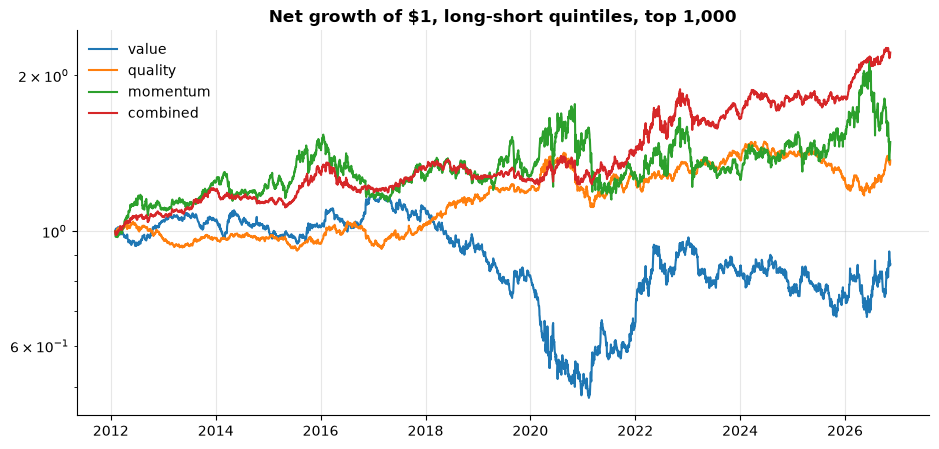

In [6]:
nets = pl.DataFrame({"date": strategies["value"].daily["date"]})
for n, b in strategies.items():
    nets = nets.join(b.daily.select("date", pl.col("net").alias(n)), on="date", how="left")
print("Correlation of daily net returns:")
print(nets.drop("date").corr().with_columns(pl.all().round(2)).with_columns(
    pl.Series("strategy", list(strategies))).select("strategy", *strategies))
fig, ax = plt.subplots(figsize=(11, 5))
for n, b in strategies.items():
    ax.plot(b.daily["date"], b.daily["nav"], label=n)
ax.set_yscale("log")
ax.set_title("Net growth of $1, long-short quintiles, top 1,000")
ax.legend()
plt.show()

Value alone lost money in large caps over this period (a 60% drawdown), quality and momentum
earned modest returns, and the combination beats all three: value and momentum are negatively
correlated (-0.51), so their losing streaks offset. Diversification across signals is the main
reason to combine them.

## 4 · Long and short legs, exposures

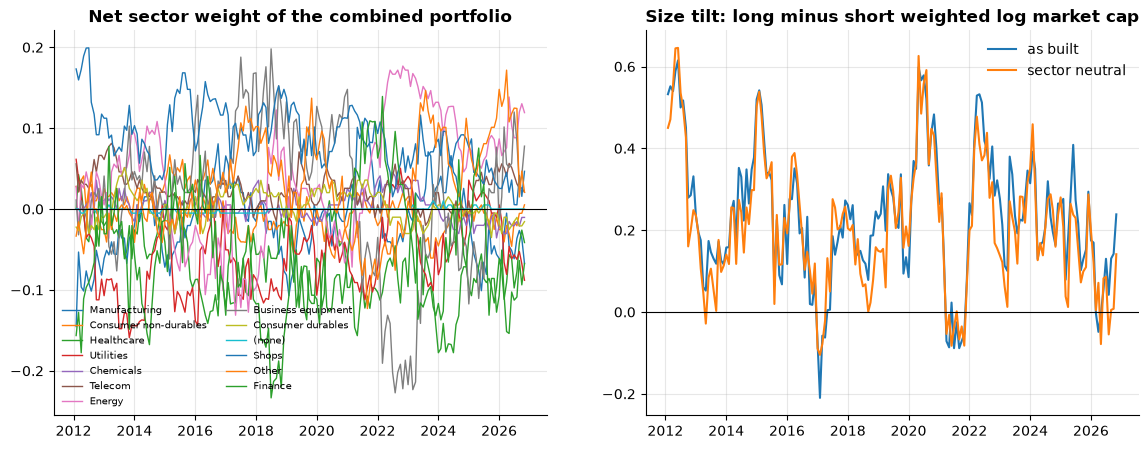

date,long_names,short_names,gross,net
date,u32,u32,f64,f64
2026-09-01,192,191,2.0,-1.9429e-16
2026-10-01,192,192,2.0,1.3878e-17
2026-11-02,193,193,2.0,0.0


In [7]:
ex = bt.exposures()
sectors = [c for c in ex.columns if c not in ("date", "long_names", "short_names", "gross", "net", "size_tilt")]
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
for c in sectors:
    ax1.plot(ex["date"], ex[c], lw=1, label=c)
ax1.axhline(0, color="black", lw=0.8)
ax1.set_title("Net sector weight of the combined portfolio")
ax1.legend(fontsize=7, ncol=2)
sn = eng.run(quantile_weights(sig, "combined", q=0.2, sector_neutral=True)).exposures()
ax2.plot(ex["date"], ex["size_tilt"], label="as built")
ax2.plot(sn["date"], sn["size_tilt"], label="sector neutral")
ax2.axhline(0, color="black", lw=0.8)
ax2.set_title("Size tilt: long minus short weighted log market cap")
ax2.legend()
plt.show()
ex.select("date", "long_names", "short_names", "gross", "net").tail(3)

The portfolio carries sector bets of up to 20% of capital (long retailers, short healthcare
and technology at times), which sector-neutral weights remove. The size tilt is positive most
of the time: the long side holds larger companies than the short side, because profitable
companies with strong momentum tend to be big. That is why cap weighting does not hurt here.

## 5 · Capacity

With an AUM, each trade also pays square-root market impact: daily volatility x
sqrt(trade size / average daily dollar volume). No liquidity floor here; the cost model
charges illiquid names.

In [8]:
rows, runs = [], {}
with timed("capacity"):
    for aum in [None, 1e7, 1e8, 1e9, 1e10]:
        b = eng.run(w, costs=CostModel(aum=aum))
        runs[aum] = b
        rows.append({"aum_musd": aum / 1e6 if aum else 0.0, **{k: v for k, v in show(b, str(aum)).items()
                                                             if k in ("net_return", "net_sharpe", "cost_drag")}})
table(rows)

capacity: 186.34 s


aum_musd,net_return,net_sharpe,cost_drag
f64,f64,f64,f64
0.0,0.055,0.59,0.008
10.0,0.047,0.514,0.016
100.0,0.032,0.364,0.032
1000.0,-0.007,-0.022,0.071
10000.0,-0.083,-0.73,0.147


Impact adds under a point a year at $10 million and about 2.3 points at $100 million (net
Sharpe 0.36); from $1 billion the book loses money after costs. A monthly, equal-weighted book
of about 400 large and mid caps turning over 11 times a year is a small-capacity strategy:
larger money would need slower turnover, cap-tilted weights or a trade-cost-aware optimizer.

**Cost warnings.** A trade costing more than 100 bp per unit traded is listed in
`Backtest.cost_warnings` (and reported once as a warning). At $100 million:

In [9]:
cw = runs[1e8].cost_warnings
print(f"{cw.height} trades in {cw['security_id'].n_unique()} securities, "
      f"{cw['cost'].sum() / runs[1e8].trades['cost'].sum():.0%} of all trading costs")
(cw.group_by("security_id", "ticker").agg(pl.len().alias("trades"), pl.col("cost").sum().alias("cost"),
                                          (pl.col("spread_bps") + pl.col("impact_bps")).max().round(0).alias("worst_bps"),
                                          pl.col("adv").median().round(0).alias("median_adv"),
                                          pl.col("date").min().alias("first"), pl.col("date").max().alias("last"))
 .sort("cost", descending=True).head(15))

580 trades in 132 securities, 12% of all trading costs


security_id,ticker,trades,cost,worst_bps,median_adv,first,last
str,str,u32,f64,f64,f64,date,date
"""BBG000C1HL99""","""JHX""",43,0.004185,577.0,233319.0,2012-08-01,2024-04-01
"""CIK:0001191141:KNM""","""KNM""",21,0.002866,699.0,94178.0,2012-02-01,2014-05-01
"""BBG000BZ2J87""","""ATE""",13,0.002577,870.0,187202.0,2012-03-01,2013-08-01
"""BBG00MYXJJ27""","""WF""",30,0.002353,470.0,1.015251e6,2012-02-01,2025-05-01
"""BBG00QQ10GB3""","""CAN""",27,0.002292,759.0,8.112996e6,2020-05-01,2026-06-01
"""CIK:0001681941:WINS""","""WINS""",4,0.002055,1394.0,1.151626e6,2017-01-03,2017-04-03
"""BBG000BZPXB7""","""NMR""",20,0.001655,244.0,1.499767e6,2012-02-01,2024-11-01
"""SYM:NBG:2003-09-10""","""NBG""",15,0.001463,573.0,3.662772e6,2012-02-01,2015-08-03
"""BBG000BCWG90""","""KEP""",19,0.001438,266.0,1.765843e6,2020-03-02,2025-09-02


These are real: US listings of foreign companies that trade mainly at home (James Hardie,
Woori, Nomura, KEPCO, ICL, Advantest) and thin-float companies. The first run of this table
also showed twelve data errors, now fixed in vinculum (decision 0004). In ten of them, ADSs
that Massive types as common stock were valued as if one ADS were one share (FANH, PLL, MFH,
TAOM, SOS and others), turning small companies into multi-billion ones; the other two were US
share counts. A thirteenth turned up while fixing them: LATAM's old ADS, shown at up to
$2.4T in 2020 because its counts were scaled to the 1,000 times as many shares it issued in
2022, was bought at the 200 bp spread cap with no recorded volume. A liquidity floor would not have caught them all (several traded over $1 million
a day), which is why the backtester reports such trades instead of filtering them.

## 6 · Long-only

The 100 best names on the combined score, equal weighted, against SPY (beta and alpha come
from daily returns against SPY).

In [10]:
lo = eng.run(top_n_weights(sig, "combined", n=100))
spy = eng.market(lo.daily["date"].min(), lo.daily["date"].max())
spy_ann = float((1 + spy["ret"]).product()) ** (252 / spy.height) - 1
s = lo.summary().filter(pl.col("series") == "net").select("ann_return", "ann_vol", "sharpe", "max_drawdown",
                                                         "turnover_per_year", "cost_drag", "beta", "alpha")
print(f"SPY over the same period: {spy_ann:.1%} a year")
s.with_columns(pl.col(pl.Float64).round(3))

SPY over the same period: 14.5% a year


ann_return,ann_vol,sharpe,max_drawdown,turnover_per_year,cost_drag,beta,alpha
f64,f64,f64,f64,f64,f64,f64,f64
0.147,0.203,0.777,-0.403,6.395,0.003,1.092,-0.006


Long-only, the top 100 roughly matched SPY (14.7% against 14.5% a year) with a beta of 1.1
and no alpha. The long-short result comes mostly from the bottom of the ranking lagging, not
from the top beating the index.

## 7 · Caveats

- **One period, one universe**: 2012-2026, the 1,000 largest US-listed companies. The signals'
  directions come from older studies; several did little here.
- **Costs are partly models**: spreads are fitted on measured trades and quotes (424 days,
  2003-2026), impact comes from a square-root law, a flat borrow
  rate with a hard-to-borrow surcharge. Real fills, borrow recalls and short squeezes are not
  in the data.
- **Delisting returns are a rule of thumb** (Shumway's -30% after a collapse); recoveries in
  bankruptcy are unknown here.
- **No risk model**: positions are equal weighted within quintiles; beta, sector and size
  exposures are reported, not controlled (sector-neutral weights are the exception). Risk
  models and optimization are planned for `borg-queen`.
- **Monthly signals at month-end closes**: daily signals work too (any dates in the weights),
  but the price signals' panel takes longer to build.